In [ ]:
# !pip install git+https://github.com/huggingface/diffusers.git
# !pip install transformers accelerate gguf bitsandbytes ipykernel pillow
!pip install ipywidgets

In [7]:
import torch
import gc
from PIL import Image
from transformers import AutoModelForCausalLM, BitsAndBytesConfig
from diffusers import Flux2KleinPipeline, Flux2Transformer2DModel, GGUFQuantizationConfig

device = "cuda"
dtype = torch.float16

print(f"Đang sử dụng GPU: {torch.cuda.get_device_name(0)}")
print(f"VRAM khả dụng: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")

Đang sử dụng GPU: NVIDIA GeForce RTX 3050 Laptop GPU
VRAM khả dụng: 4.00 GB


In [8]:
print("🚀 Đang nạp FLUX.2 [klein] 4B chế độ tối ưu cho RTX 3050 4GB...")

my_token="hf_REDACTED_SECURITY_AUDIT" # Điền token Hugging Face của bạn

# 1. Nén Text Encoder Qwen3-4B xuống 4-bit NF4 và giữ trên RAM (CPU)
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=dtype,
)

text_encoder = AutoModelForCausalLM.from_pretrained(
    "black-forest-labs/FLUX.2-klein-4B",
    subfolder="text_encoder",
    quantization_config=bnb_config,
    torch_dtype=dtype,
    device_map="cpu",          # Giữ trên RAM máy để dành trọn 4GB VRAM cho Transformer
    low_cpu_mem_usage=True,
    token=my_token,
)

# 2. Load Transformer bản GGUF Q4_K_M (~2.6GB)
gguf_file = "https://huggingface.co/unsloth/FLUX.2-klein-4B-GGUF/blob/main/flux-2-klein-4b-Q4_K_M.gguf"
transformer = Flux2Transformer2DModel.from_single_file(
    gguf_file,
    config="black-forest-labs/FLUX.2-klein-4B",
    subfolder="transformer",
    quantization_config=GGUFQuantizationConfig(compute_dtype=dtype),
    torch_dtype=dtype,
    token=my_token,
)

# 3. Khởi tạo Pipeline
pipe = Flux2KleinPipeline.from_pretrained(
    "black-forest-labs/FLUX.2-klein-4B",
    transformer=transformer,
    text_encoder=text_encoder,
    torch_dtype=dtype,
    token=my_token,
)

# 4. Tự động luân chuyển VRAM (Khắc phục lỗi KeyError: None)
pipe.enable_model_cpu_offload()

# Tối ưu bộ giải mã VAE chống tràn VRAM khi xuất file ảnh
pipe.vae.enable_tiling()
pipe.vae.enable_slicing()

print("✅ Đã nạp xong Pipeline! Sẵn sàng sinh ảnh hiện trường / vật chứng.")

🚀 Đang nạp FLUX.2 [klein] 4B chế độ tối ưu cho RTX 3050 4GB...


Loading pipeline components...: 100%|██████████| 5/5 [00:01<00:00,  4.90it/s]

✅ Đã nạp xong Pipeline! Sẵn sàng sinh ảnh hiện trường / vật chứng.


🎨 Đang vẽ ảnh... (Với 4 steps, RTX 3050 sẽ mất khoảng 15-30 giây)


100%|██████████| 4/4 [02:35<00:00, 38.96s/it]


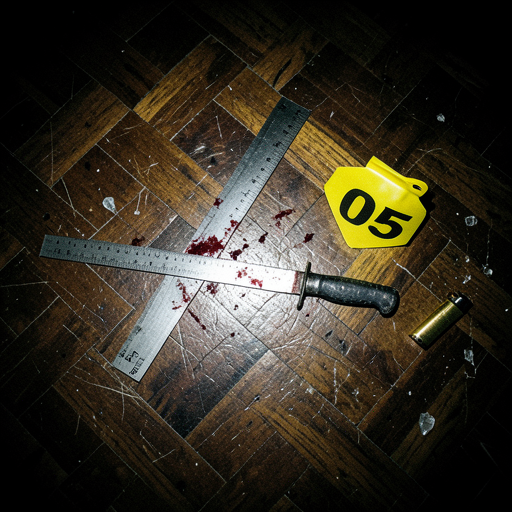

In [13]:
# --- CHỈNH SỬA PROMPT TẠI ĐÂY ---
prompt = """
A gritty forensic photograph taken from a top-down angle (overhead view), documenting physical evidence on a dark, scratched vintage parquet floor. In the center, a single bloodstained steel hunting knife (only one knife, with a worn black handle and a straight metallic blade) lies flat, and there are dried dark blood stains splattered on its blade and the floor around it. Next to the knife's edge, a yellow plastic forensic tent marker with the bold printed number "05" is placed on the floor. Lying perfectly parallel alongside the knife is a straight, flat L-shaped forensic ruler (forensic scale) with visible black measurement markings, aligning with the knife's length. Scattered nearby are a dropped metallic brass lighter and broken glass shards. Strong directional flashlight glare cuts through the dark, highlighting the metallic knife and the ruler. Camera grain, realistic, authentic police case file photo style.
"""
# ------------------------------

print("🎨 Đang vẽ ảnh... (Với 4 steps, RTX 3050 sẽ mất khoảng 15-30 giây)")

generator = torch.Generator(device="cpu").manual_seed(42)

with torch.inference_mode():
    image = pipe(
        prompt=prompt,
        width=512,              # Có thể nâng lên 768 nếu muốn độ chi tiết cao hơn
        height=512,
        num_inference_steps=4,  # Bản Klein chưng cất: 4 steps là chuẩn đẹp nhất
        guidance_scale=1.0,     # Bắt buộc 1.0 cho bản Klein distilled
        generator=generator,
    ).images[0]

# Giải phóng bộ nhớ đệm
gc.collect()
torch.cuda.empty_cache()

# Hiển thị và lưu ảnh
display(image)
# image.save("test_evidence.png")
# print("💾 Đã lưu ảnh thành công vào test_evidence.png!")